# import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warmings

ModuleNotFoundError: No module named 'warmings'

In [7]:
import warnings

warnings.filterwarnings("ignore")

Normal distribition and gaussian distribution -> majority of datapoint is clustered around mean.

In [3]:
mu=0
sigma=0.1

In [9]:
s=np.random.normal(mu,sigma,size=10000)
len(s)

10000

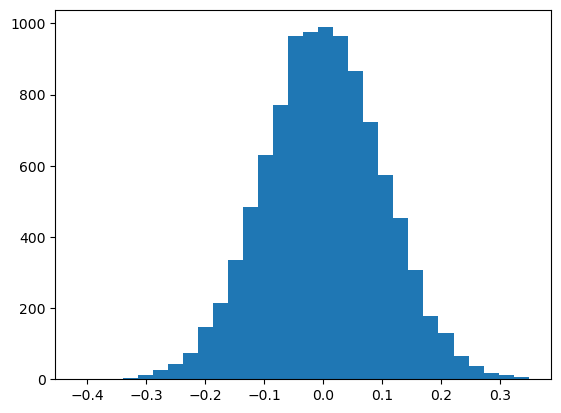

In [10]:
plt.hist(s,30)
plt.show()

<Axes: ylabel='Density'>

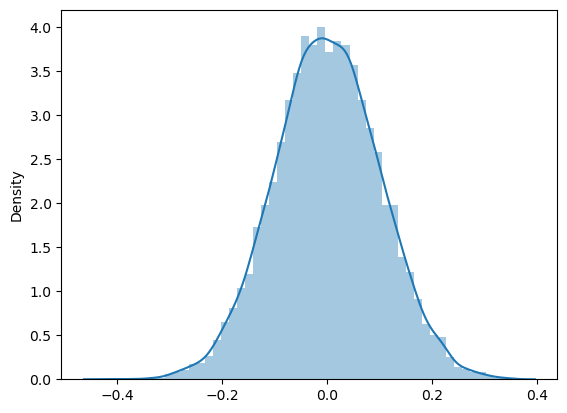

In [11]:
sns.distplot(s)

Uniform distribution 
All the outcomes has equal probability to occur in a range

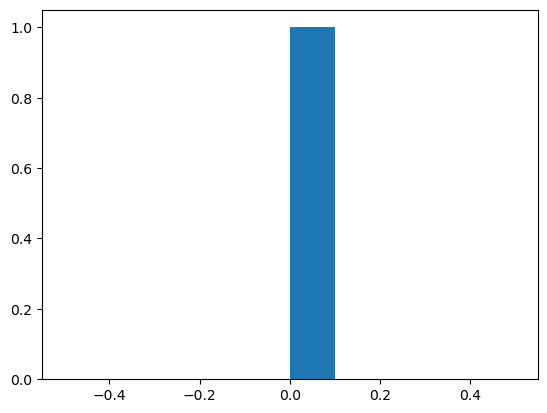

In [13]:
np.random.uniform(0,1,10000)
plt.hist(mu)
plt.show()

<Axes: ylabel='Density'>

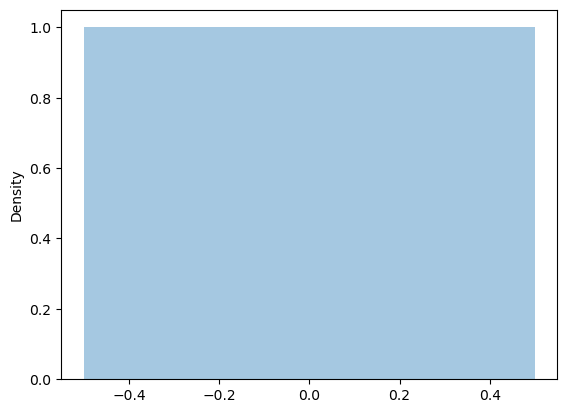

In [14]:
sns.distplot(mu)

log normal distribution

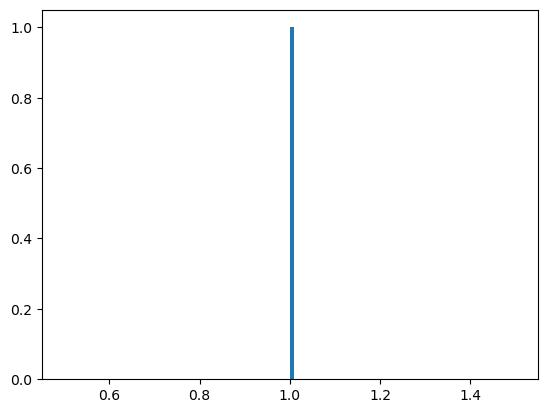

In [15]:
l=np.random.lognormal(mean=0,sigma=0.5,size=1000)
o=l[np.where(abs(l)<5)]
plt.hist(1,bins=100)
plt.show()

<Axes: >

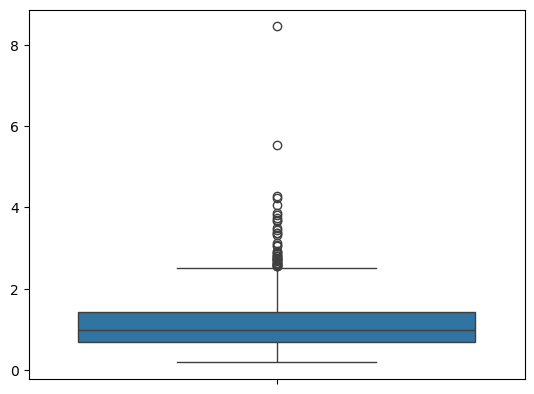

In [16]:
sns.boxplot(l)

In [17]:
#since log normal are right skewed so outliers are present.

<Axes: ylabel='Density'>

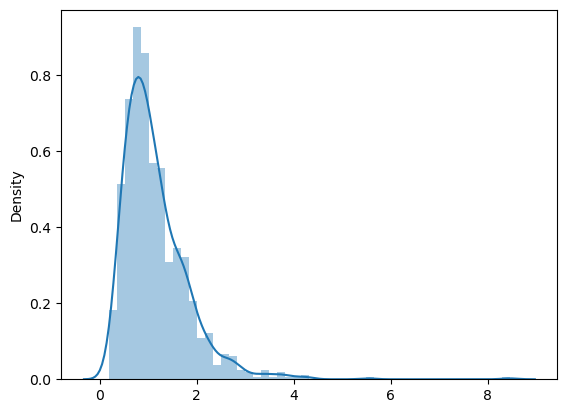

In [18]:
sns.distplot(l)

In [19]:
#lognormal becomes normal distribution if we take distplot

<Axes: ylabel='Density'>

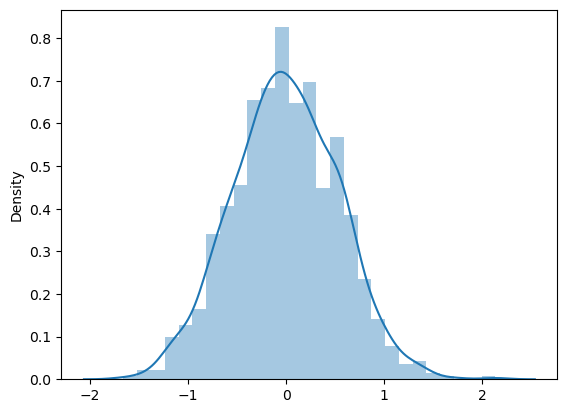

In [21]:
sns.distplot(np.log(l))

<Axes: ylabel='Density'>

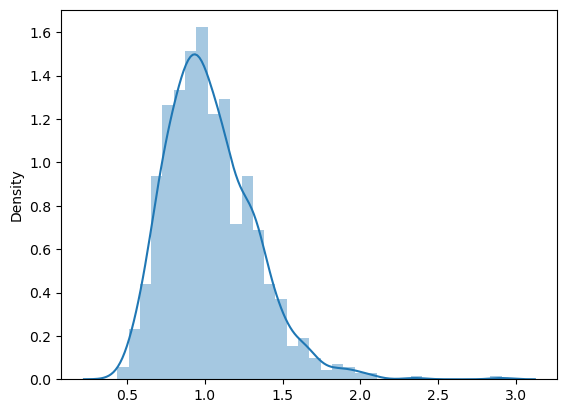

In [22]:
#square root transformation
sns.distplot(np.sqrt(l))

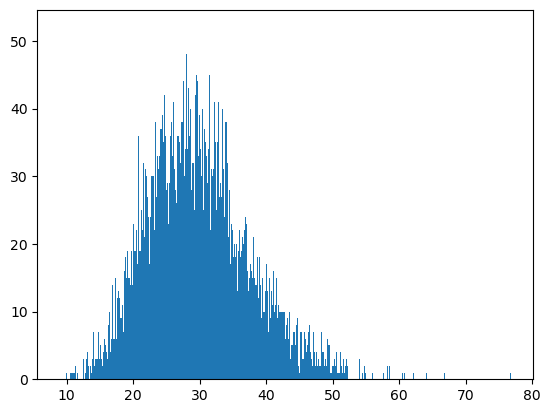

In [3]:
#chi-square distribution
c=np.random.chisquare(df=30,size=10000)
c=c[np.where(abs(c)<100)]
plt.hist(c,bins=1000)
plt.show()

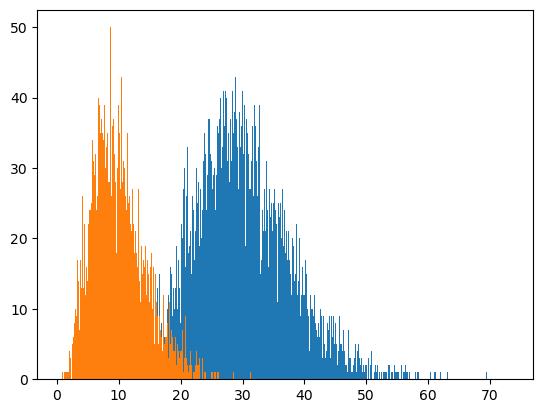

In [5]:
#multiple chi-square distribution in one plot
c=np.random.chisquare(df=30,size=10000)
d=np.random.chisquare(df=10,size=10000)
c=c[np.where(abs(c)<100)]
d=d[np.where(abs(d)<100)]
plt.hist(c,bins=1000)
plt.hist(d,bins=1000)
plt.show()

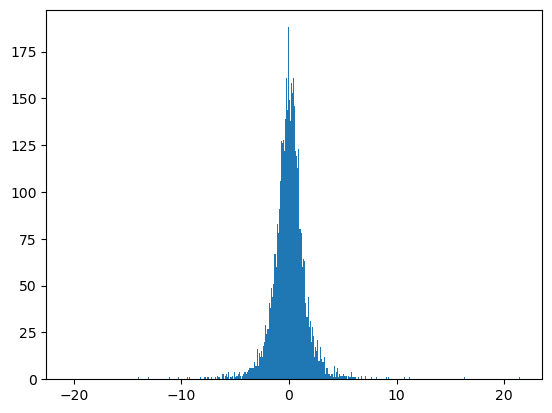

In [6]:
# T Distribution
t=np.random.standard_t(df=3,size=10000)
t=t[np.where(abs(t)<100)]
plt.hist(t,bins=1000)
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

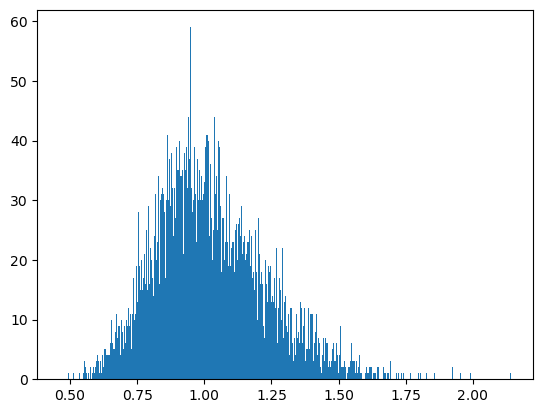

In [8]:
#F DISTRIBUTION
f=np.random.f(dfnum=100,dfden=100,size=10000)
f=f[np.where((abs(f))<10)]
plt.hist(f,bins=1000)
plt.show

DISCCRETE DISTRIBUTION

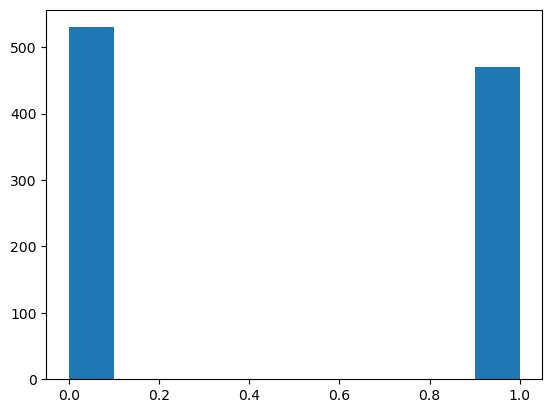

In [9]:
#Bernouli distribution -> Binomial Distribution with one trial is bernoulli distribution
b=np.random.binomial(n=1,p=0.5,size=1000)
plt.hist(b)
plt.show()

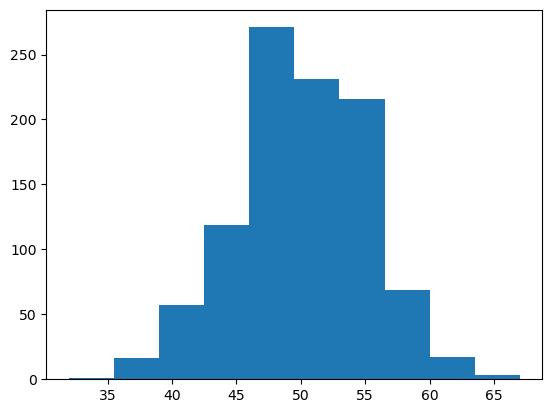

In [10]:
#Binomial Distribution
b=np.random.binomial(n=100,p=0.5,size=1000)
plt.hist(b)
plt.show()

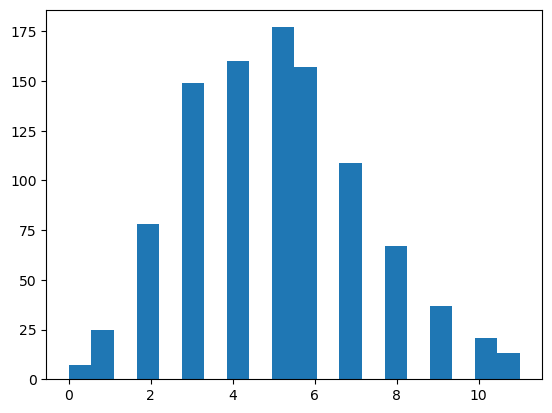

In [11]:
#Poisson Distribution
p=np.random.poisson(lam=5,size=1000)
plt.hist(p,bins=20)
plt.show()

In [12]:
population=np.random.randint(10,20,50)
population

array([14, 14, 14, 18, 15, 10, 19, 16, 13, 16, 19, 13, 13, 16, 18, 18, 15,
       14, 11, 10, 15, 19, 16, 19, 10, 16, 13, 16, 19, 16, 18, 13, 18, 19,
       15, 14, 10, 18, 13, 17, 17, 14, 11, 18, 13, 13, 12, 19, 18, 19],
      dtype=int32)

In [13]:
len(population)

50

In [14]:
import statistics
print("The mean of the population ",np.mean(population))
print("The median of the population ",np.median(population))
print("The mode of the population ",statistics.mode(population))


The mean of the population  15.28
The median of the population  15.5
The mode of the population  18


In [16]:
#To Select a sample
sample1=np.random.choice(population,20)
sample2=np.random.choice(population,20)
sample3=np.random.choice(population,20)
sample4=np.random.choice(population,20)

In [20]:
mean_of_samples=[]
all_samples=[sample1,sample2,sample3,sample4]
for sample in all_samples:
    mean_of_samples.append(np.mean(sample))
    mean_of_samples

3000

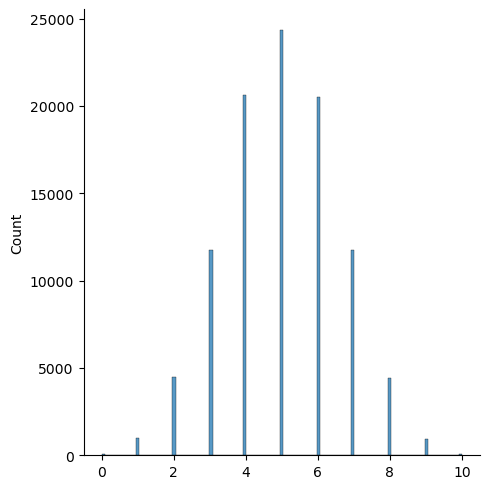

In [22]:
#Central Limit Theorem
population=np.random.binomial(10,0.5,100000)
len(population)
sns.displot(population)
sample_size=int(len(population)*0.030)
sample_size

In [23]:
mean_of_samples=[]
for i in range(1,1000):
    sample=np.random.choice(population,size=sample_size)
    mean_of_samples.append(np.mean(sample))
    mean_of_samples
len(mean_of_samples)

999

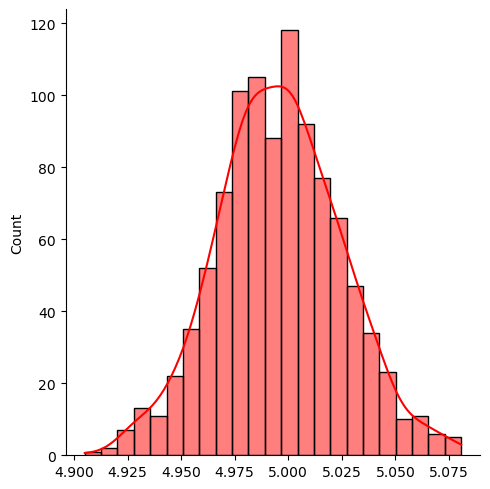

In [24]:
sns.displot(mean_of_samples,kde=True,color="red")

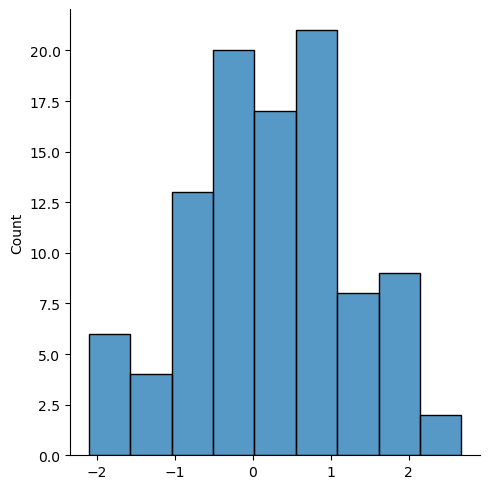

In [25]:
#Z Test
population =np.random.randn(100)
population
sns.displot(population)

In [26]:
np.mean(population),np.std(population)

(np.float64(0.219262970500614), np.float64(1.0006676712280833))

Z Test-> for hypothesis testing-> frame the hypothesis-> alpha, type of test->test statistics or pvalue approach->test critical-> conclusion


In [27]:
null_mean=0.09 #hypothesis
#alternate>=0.09

In [28]:
from statsmodels.stats.weightstats import ztest
zscore,pvalue=ztest(population,value=null_mean,alternative='larger')
zscore

np.float64(1.2852921647138849)

In [29]:
pvalue

np.float64(0.09934510358019999)

In [30]:
if pvalue<=0.05:
    print("reject null hypothesis")
else:
    print("fail to reject null hypothesis")
    

fail to reject null hypothesis


In [5]:
import scipy.stats as stats
sample_mean=100
population_mean=90
population_std=16
sample_size=60
alpha=0.05
#sample_size=50
zscore=(sample_mean-population_mean)/(population_std/np.sqrt(50))
print("the zscore is ",zscore)

the zscore is  4.419417382415922


In [33]:
#for zcritical scipy.stats
#norms->normal distribution
#ppf->percent point function (inverse of cummulative distribution function)
zcritical=stats.norm.ppf(1-alpha)
zcritical

np.float64(1.6448536269514722)

In [34]:
if zscore>zcritical:
    print("Reject null hypothesis")
else:
     print(" Fail to Reject null hypothesis")
#using scipy.stats pvalue approach
pvalue=1-stats.norm.cdf(zscore)
if pvalue<=0.05:
     print("Reject null hypothesis")
else:
     print(" Fail to Reject null hypothesis")

Reject null hypothesis
Reject null hypothesis


T test 

In [ ]:
'''Sample size<30 or sigma or population not given
one_sample_t test->with respect to one independent variable
two sample test-> with respect to two independent variable'''

In [35]:
#Paired T Test->Two samples from the population at different interval of time
#one sample  t-test
population=np.random.randint(10,50,50)
population

array([33, 12, 27, 15, 34, 13, 27, 38, 20, 30, 16, 29, 23, 45, 34, 41, 27,
       11, 36, 42, 29, 15, 33, 30, 31, 24, 39, 15, 19, 33, 21, 35, 20, 10,
       13, 37, 12, 46, 25, 24, 19, 35, 12, 24, 28, 43, 17, 18, 23, 35],
      dtype=int32)

In [36]:
#for t test scipy.stats
null_value=25 #the mean of population is 25 
stats.ttest_1samp(sample,null_value)
p_value=0.19
if p_value<=0.05:
    print("reject the null hypothesis")
else:
    print("fail to reject null hypothesis")

fail to reject null hypothesis


Difference between one sample t test and two sample t test

In [38]:
#Two sample t test
virat_kohli_score=np.random.choice(population,20)
virat_kohli_score

array([15, 41, 10, 35, 20, 19, 46, 31, 37, 24, 21, 13, 35, 10, 11, 27, 35,
       34, 11, 31], dtype=int32)

In [40]:
rohit_sharma_score=[13,25,48,28,19,12,13,18,98,40,18,23,34,33,45,58,46,27,50,49]
np.mean(rohit_sharma_score),np.mean(virat_kohli_score)
stats.ttest_ind(virat_kohli_score,rohit_sharma_score)

TtestResult(statistic=np.float64(-1.8179197695068634), pvalue=np.float64(0.07696670815400421), df=np.float64(38.0))

In [42]:
p_value=0.329
if p_value<=0.05:
    print("reject the null hypothesis")
else:
    print("fail to reject null hypothesis")

fail to reject null hypothesis


In [14]:
import numpy as np
from scipy import stats
#Paired test
rohit_score_first_inning=[31,36,46,24,48,46,47,47,16,35,45,37,24,29,27,29,32,26]
rohit_score_second_inning=[31,76,46,24,48,23,49,47,37,35,45,37,74,39,27,42,49,37]
np.mean(rohit_score_first_inning),np.mean(rohit_score_second_inning)
stats.ttest_rel(rohit_score_first_inning,rohit_score_second_inning)
p_value=0.17
if p_value<=0.05:
    print("reject the null hypothesis")
else:
    print("fail to reject null hypothesis")

fail to reject null hypothesis


In [9]:

import numpy as np
import statistics as stats
from scipy import stats as scipy_stats

# Paired test
rohit_score_first_inning = [31,36,46,24,48,46,47,47,16,35,45,37,24,29,27,29,32]

rohit_score_second_inning = [31,76,46,24,48,23,49,47,37,35,45,37,74,39,27,42,49,37]

# Check observations
print(len(rohit_score_first_inning))
print(len(rohit_score_second_inning))

# Remove the extra observation only if it is confirmed to be an error
rohit_score_second_inning = rohit_score_second_inning[:17]

# Calculate means
print("First innings mean:", np.mean(rohit_score_first_inning))
print("Second innings mean:", np.mean(rohit_score_second_inning))

# Paired t-test
result = scipy_stats.ttest_rel(
    rohit_score_first_inning,
    rohit_score_second_inning
)

print("T-statistic:", result.statistic)
print("P-value:", result.pvalue)


17
18
First innings mean: 35.23529411764706
Second innings mean: 42.88235294117647
T-statistic: -1.8519063421502702
P-value: 0.08258226357964346


try using zscore and z critical method

In [15]:

import numpy as np
from scipy.stats import norm

# Data
first = np.array([31,36,46,24,48,46,47,47,16,35,45,37,24,29,27,29,32,26])

second = np.array([31,76,46,24,48,23,49,47,37,35,45,37,74,39,27,42,49,37])

# Step 1: Calculate paired differences
d = first - second

# Step 2: Mean and standard deviation
mean_d = np.mean(d)
std_d = np.std(d, ddof=1)

# Step 3: Sample size
n = len(d)

# Step 4: Calculate standard error
SE = std_d / np.sqrt(n)

# Step 5: Calculate Z-score
z_score = mean_d / SE

# Step 6: Calculate Z-critical
alpha = 0.05
z_critical = norm.ppf(1 - alpha/2)

print("Mean difference:", mean_d)
print("Standard deviation:", std_d)
print("Standard error:", SE)
print("Z-score:", z_score)
print("Z-critical:", z_critical)

# Step 7: Decision
if abs(z_score) > z_critical:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")


Mean difference: -7.833333333333333
Standard deviation: 16.536056859801498
Standard error: 3.897585979883989
Z-score: -2.0097910280266587
Z-critical: 1.959963984540054
Reject the null hypothesis


In [6]:
data=[1,2,3,4,5]
data

[1, 2, 3, 4, 5]

In [7]:
import pandas as pd
import numpy as np
import seaborn as sns

In [8]:
import warnings
warnings.filterwarnings("ignore")

In [9]:
np.mean(data)
df=sns.load_dataset('tips')
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [10]:
np.mean(df['total_bill'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [11]:
np.median(data)

np.float64(3.0)

In [12]:
np.median(df['total_bill'])

np.float64(17.795)

In [13]:
#mean is affected by outliers
data=[1,2,3,4,500]
np.mean(data)
#median is not affected by outliers

np.float64(102.0)

In [14]:
np.median(data)

np.float64(3.0)

In [15]:
#numpy don't have mode
data=[1,2,1,100,3,4,78]
np.mode(data)

AttributeError: module 'numpy' has no attribute 'mode'

In [17]:
import statistics
statistics.mode(data)
df.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [18]:
np.percentile(data,[25,30,99])
data.append(-800)
data.append(600)
data

[1, 2, 1, 100, 3, 4, 78, -800, 600]

<Axes: >

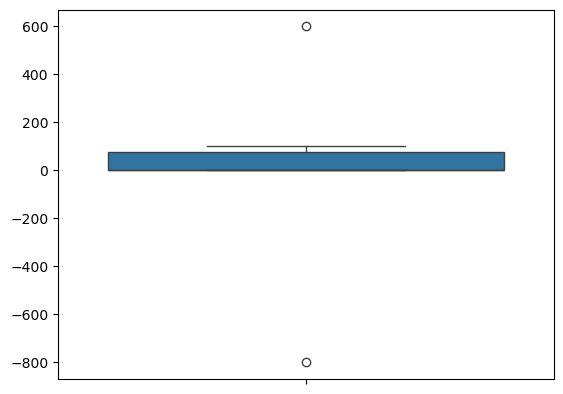

In [19]:
sns.boxplot(data)


In [20]:
np.var(data)

np.float64(112900.17283950618)

In [21]:
np.std(data)

np.float64(336.0062095252202)

In [22]:
np.mean(data)

np.float64(-1.2222222222222223)

In [23]:
statistics.variance(data) #sample variance
statistics.pvariance(data)

112900.17283950618

In [24]:
import math
math.sqrt(statistics.pvariance(data))

336.0062095252202

In [25]:
df.corr(numeric_only=True)

,total_bill,tip,size
total_bill,1.000000,0.675734,0.598315
tip,0.675734,1.000000,0.489299
size,0.598315,0.489299,1.000000


<Axes: >

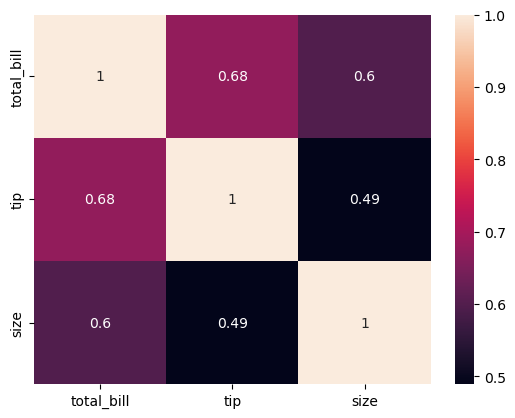

In [26]:
corr=df.corr(numeric_only=True)
sns.heatmap(corr,annot=True)

In [27]:
df.cov(numeric_only=True)

,total_bill,tip,size
total_bill,79.252939,8.323502,5.065983
tip,8.323502,1.914455,0.643906
size,5.065983,0.643906,0.904591


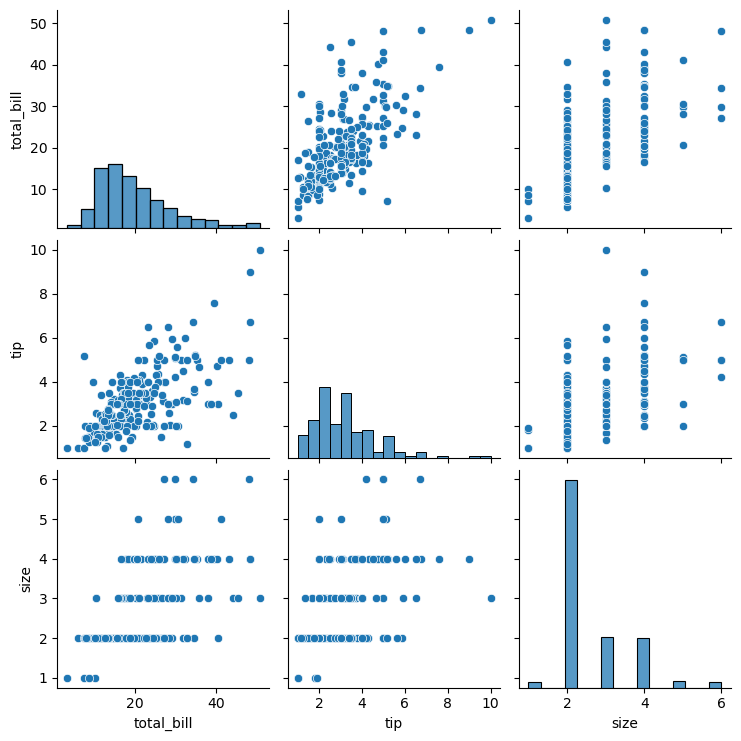

In [28]:
sns.pairplot(df)

<Axes: ylabel='Count'>

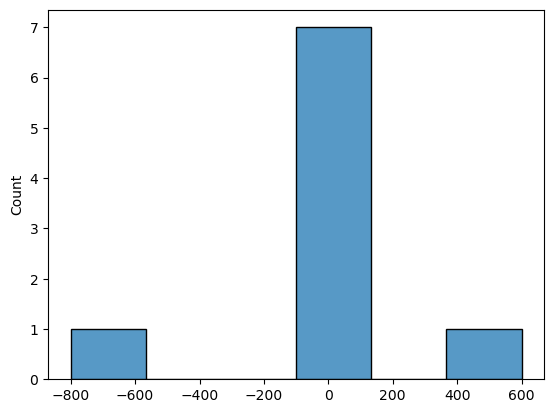

In [29]:
sns.histplot(data)

<Axes: ylabel='Count'>

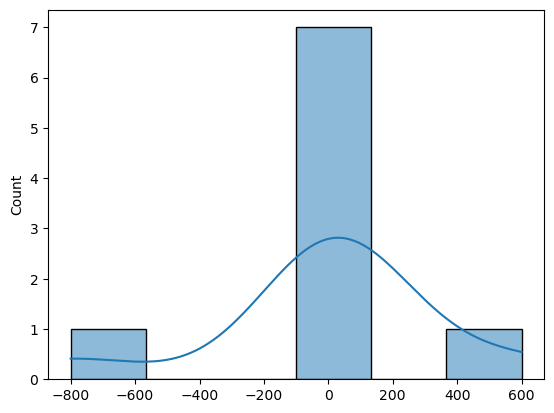

In [30]:
sns.histplot(data,kde=True)

<Axes: xlabel='total_bill', ylabel='Count'>

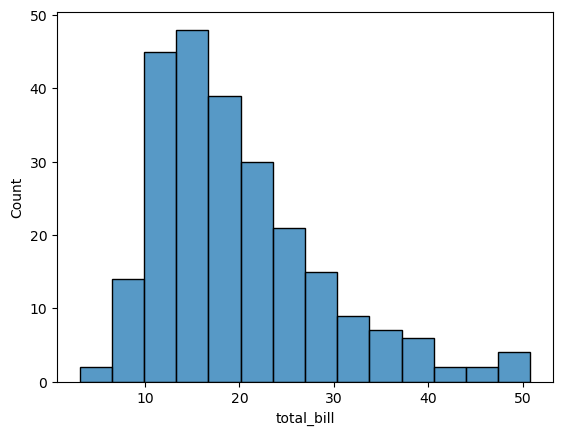

In [33]:
sns.histplot(df['total_bill'])

<Axes: xlabel='total_bill', ylabel='Count'>

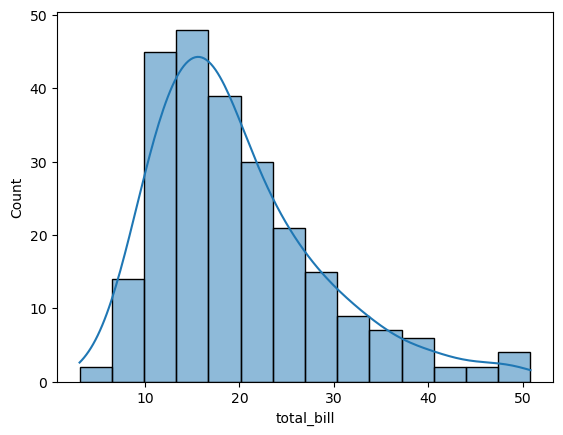

In [34]:
#kde=kernel density instrumation
sns.histplot(df['total_bill'],kde=True)

In [35]:
np.random.normal(0.5,0.2,1000)

array([ 0.60072275,  0.38616726,  0.18655045,  0.41358823,  0.89383733,
        0.66357581,  0.38383126,  0.12653919,  0.76500872,  0.60490075,
        0.30348657,  0.29032068,  0.82615057,  0.70184948,  0.57060342,
        0.68886718,  0.40473934,  0.46758479,  0.36278304,  0.62664547,
        0.32505408,  0.51652374,  0.53843392,  0.44354604,  0.18196011,
        0.6209484 ,  0.51852965,  0.53775254,  0.15718256,  0.53295461,
        0.40916262,  0.42421618,  0.22122456,  0.42913247,  0.07148988,
        0.29508524,  0.45045969,  0.5261831 ,  0.2782898 ,  0.63193504,
        0.46392718,  0.71794351,  0.811334  ,  0.32378394,  0.32179353,
        0.39666537,  0.3410123 ,  0.88497323,  0.42206517,  0.48554348,
        0.3593762 ,  0.65588348,  0.40956579,  0.22832356,  0.471855  ,
        0.81426041,  0.42488789,  0.72115452,  0.48970407,  0.47371965,
        0.48350883,  0.41424787,  0.68650015,  0.20518949,  0.89614968,
        0.55858578,  0.69865723,  0.44133565,  0.62804133,  0.28

Chi-Squared Test

In [36]:
import pandas as pd
import numpy as np
import seaborn as sns

In [38]:
import warnings 
warnings.filterwarnings('ignore')

In [39]:
data=sns.load_dataset('tips')
data

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [40]:
data[['sex','smoker']]

,sex,smoker
0,Female,No
1,Male,No
2,Male,No
3,Male,No
4,Female,No
...,...,...
239,Male,No
240,Female,Yes
241,Male,Yes
242,Male,No


In [41]:
#summarization of data using crosstab
data_table=pd.crosstab(data['sex'],data['smoker'])
observed_values=data_table.values
observed_values

array([[60, 97],
       [33, 54]])

In [43]:
import scipy.stats as stats
expected_values=stats.chi2_contingency(observed_values)
expected_values

Chi2ContingencyResult(statistic=np.float64(0.0), pvalue=np.float64(1.0), dof=1, expected_freq=array([[59.84016393, 97.15983607],
       [33.15983607, 53.84016393]]))

In [44]:
stats_test,p,dof,expected_values=stats.chi2_contingency(observed_values)
expected_values

array([[59.84016393, 97.15983607],
       [33.15983607, 53.84016393]])

In [45]:
#using chisquare critical method
dof=1

In [46]:
from scipy.stats import chi2
for i in zip (observed_values,expected_values):
    print(i)

(array([60, 97]), array([59.84016393, 97.15983607]))
(array([33, 54]), array([33.15983607, 53.84016393]))


In [49]:
chisquare_test=sum([(o-e)**2/e for o,e in zip (observed_values,expected_values)])
chisquare_test

array([0.00119737, 0.00073745])

In [50]:
chisquare_stats=chisquare_test[0]+chisquare_test[1]
dof

1

In [51]:
alpha=0.05

In [52]:
chi2_critical=chi2.ppf(1-alpha,dof)
chi2_critical

np.float64(3.841458820694124)

In [53]:
if chisquare_stats>=chi2_critical:
    print("reject the null hypothesis, there is relationship between two categorical variable")
else:
    print("fail to reject null hypothesis,no relationship")

fail to reject null hypothesis,no relationship


In [54]:
#pvalue method
p_value=1-chi2.cdf(x=chisquare_stats,df=dof)
if p_value<=0.05:
      print("reject the null hypothesis, there is relationship between two categorical variable")
else:
    print("fail to reject null hypothesis,no relationship")


fail to reject null hypothesis,no relationship


In [56]:
expected_data=[8,5,6,8,5,7,6]
observed_data=[7,4,7,9,4,8,6]
sum(expected_data),sum(observed_data)
chistats,pvalue=stats.chisquare(observed_values,expected_values)

In [58]:
#using chisquare critical 
critical_value=stats.chi2.ppf(1-alpha,dof)
chisqstats=chistats[0]+chistats[1]
if chisqstats>critical_value:
    print("reject the null hypothesis")
else:
    print("fail to reject")
    

fail to reject


F Test

In [59]:
#two workers -if one worker is more effective than other
worker1=[18,17,20,25,27,55,51,42,46,29]
worker2=[18,16,22,26,39,51,48,44,58,12]
fstats=np.var(worker1)/np.var(worker2)
fstats

np.float64(0.743155149934811)

In [60]:
df1=len(worker1)-1
df2=len(worker2)-1
df1
df2

9

In [65]:
critical_value=stats.f.ppf(q=1-alpha,dfn=df1,dfd=df2)
if fstats>critical_value:
    print("reject the null hypothesis")
else:
    print("fail to reject null hypothesis")

fail to reject null hypothesis


In [66]:

import scipy.stats as stats

alpha = 0.05
df1 = 5
df2 = 10

# F-critical value
critical_value = stats.f.ppf(
    q=1-alpha,
    dfn=df1,
    dfd=df2
)

# Calculated F-statistic
f_statistic = 3.5

if f_statistic > critical_value:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")


Reject the null hypothesis


Annova test-> used to compare the mean of 2 or more samples

In [71]:

# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import scipy.stats as stats
from io import StringIO


# ==========================================
# 2. LOAD DATASET (PlantGrowth)
# ==========================================

csv_data = """weight,group
4.17,ctrl
5.58,ctrl
5.18,ctrl
6.11,ctrl
4.50,ctrl
4.61,ctrl
5.17,ctrl
4.53,ctrl
5.33,ctrl
5.14,ctrl
4.81,trt1
4.17,trt1
4.41,trt1
3.59,trt1
5.87,trt1
3.83,trt1
6.03,trt1
4.89,trt1
4.32,trt1
4.69,trt1
6.31,trt2
5.12,trt2
5.54,trt2
5.50,trt2
5.37,trt2
5.29,trt2
4.92,trt2
6.15,trt2
5.80,trt2
5.26,trt2
"""

df = pd.read_csv(StringIO(csv_data))

print("Dataset:")
print(df.head())

print("\nDataset information:")
print(df.info())

print("\nGroup counts:")
print(df["group"].value_counts())


# ==========================================
# 3. FIND UNIQUE GROUPS
# ==========================================

groups = df.group.unique()

print("\nUnique groups:", groups)


# ==========================================
# 4. SEPARATE DATA INTO GROUPS
# ==========================================

data = {
    grp: df["weight"][df.group == grp]
    for grp in groups
}

print("\nGroup-wise data:")
print(data)


# ==========================================
# 5. CALCULATE GROUP MEANS
# ==========================================

print("\nMean weight of each group:")

for grp in groups:
    print(grp, ":", data[grp].mean())


# ==========================================
# 6. ONE-WAY ANOVA TEST
# ==========================================

f_stats, p_value = stats.f_oneway(
    data["ctrl"],
    data["trt1"],
    data["trt2"]
)

print("\nF-statistic:", f_stats)
print("P-value:", p_value)


# ==========================================
# 7. HYPOTHESIS TESTING
# ==========================================

alpha = 0.05

# H0: All group means are equal
# H1: At least one group mean is different

if p_value <= alpha:
    print("\nReject the null hypothesis")
    print("At least one group mean is significantly different")

else:
    print("\nFail to reject the null hypothesis")
    print("No significant difference found between group means")


# ==========================================
# 8. F-CRITICAL VALUE METHOD
# ==========================================

df1 = len(groups) - 1
df2 = len(df) - len(groups)

critical_value = stats.f.ppf(
    q=1-alpha,
    dfn=df1,
    dfd=df2
)

print("\nDegrees of freedom numerator:", df1)
print("Degrees of freedom denominator:", df2)
print("F-critical value:", critical_value)

if f_stats > critical_value:
    print("Reject H0 using F-critical method")
else:
    print("Fail to reject H0 using F-critical method")


Dataset:
   weight group
0    4.17  ctrl
1    5.58  ctrl
2    5.18  ctrl
3    6.11  ctrl
4    4.50  ctrl

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   weight  30 non-null     float64
 1   group   30 non-null     object 
dtypes: float64(1), object(1)
memory usage: 612.0+ bytes
None

Group counts:
group
ctrl    10
trt1    10
trt2    10
Name: count, dtype: int64

Unique groups: ['ctrl' 'trt1' 'trt2']

Group-wise data:
{'ctrl': 0    4.17
1    5.58
2    5.18
3    6.11
4    4.50
5    4.61
6    5.17
7    4.53
8    5.33
9    5.14
Name: weight, dtype: float64, 'trt1': 10    4.81
11    4.17
12    4.41
13    3.59
14    5.87
15    3.83
16    6.03
17    4.89
18    4.32
19    4.69
Name: weight, dtype: float64, 'trt2': 20    6.31
21    5.12
22    5.54
23    5.50
24    5.37
25    5.29
26    4.92
27    6.15
28    5.80
29    5.26
Name: weight, dtype